<a href="https://colab.research.google.com/github/juansepq2017-sys/Proyecto-Progra-2/blob/punto3-outliers/proyecto_creditos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Programación II — Análisis de Créditos y Datos Demográficos

**Integrantes:** Juan Sebastian Castro Castellanos · Juan Sebastian Pardo Quintero · Andres Felipe Gomez Bejarano · Juan Esteban Gil

Dataset: `DATASET_proyecto_dic.xlsx` — solicitudes de crédito con variables demográficas, financieras y de vivienda.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Carga e inspección inicial de los datos

In [9]:
from google.colab import drive
import pandas as pd

# Montar Google Drive (si ya está montado, no pasa nada)
drive.mount('/content/drive')

# Leer tu archivo de Excel
ruta_excel = '/content/drive/MyDrive/proyecto programacion /DATASET_proyecto_dic.xlsx'
df = pd.read_excel(ruta_excel)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Column1,Age,Sex,Job,Housing,Saving Account,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [10]:
print("Tamaño del conjunto (filas, columnas):", df.shape)
df.info()

Tamaño del conjunto (filas, columnas): (1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Column1           1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving Account    817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
dtypes: int64(5), object(5)
memory usage: 78.3+ KB


### Tipos de variables

In [11]:
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(exclude="number").columns.tolist()
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Numéricas: ['Column1', 'Age', 'Job', 'Credit amount', 'Duration']
Categóricas: ['Sex', 'Housing', 'Saving Account', 'Checking account', 'Purpose']


| Tipo | Variables |
|---|---|
| Numérica continua | `Credit amount` |
| Numérica discreta | `Age`, `Duration` |
| Categórica ordinal | `Job` (codificada 0–3), `Saving Account`, `Checking account` |
| Categórica nominal | `Sex`, `Housing`, `Purpose` |
| Índice (sin valor analítico) | `Column1` |

### Descripción estadística

In [12]:
df.describe()

,Column1,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [13]:
df.describe(exclude="number")

,Sex,Housing,Saving Account,Checking account,Purpose
count,1000,1000,817,606,1000
unique,2,3,4,3,8
top,male,own,little,little,car
freq,690,713,603,274,337


## 2. Manejo de datos faltantes

In [14]:
faltantes = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(1)
})
faltantes[faltantes["faltantes"] > 0]

,faltantes,porcentaje
Saving Account,183,18.3
Checking account,394,39.4


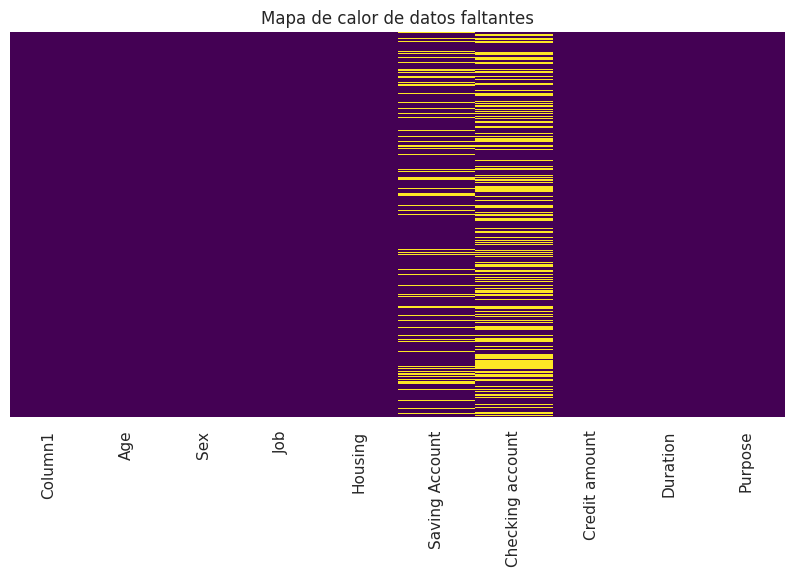

In [15]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de datos faltantes")
plt.show()

In [16]:
print("Filas con al menos un faltante:", df.isna().any(axis=1).sum())

Filas con al menos un faltante: 478


**Decisión: imputar con la categoría `"unknown"`, no eliminar.**

- `Checking account` tiene **39,4 %** de faltantes y `Saving Account` **18,3 %**. Si elimináramos filas perderíamos **478 registros (47,8 %)**, casi la mitad de la base.
- Imputar con la moda (`little`) inflaría artificialmente esa categoría y distorsionaría los análisis por ahorro/cuenta.
- Ambas son variables categóricas: crear la categoría `"unknown"` conserva todos los registros y deja explícito que la información no fue reportada (lo cual puede ser informativo en sí mismo).

In [17]:
df[["Saving Account", "Checking account"]] = df[["Saving Account", "Checking account"]].fillna("unknown")
df.isna().sum()

,0
Column1,0
Age,0
Sex,0
Job,0
Housing,0
Saving Account,0
Checking account,0
Credit amount,0
Duration,0
Purpose,0


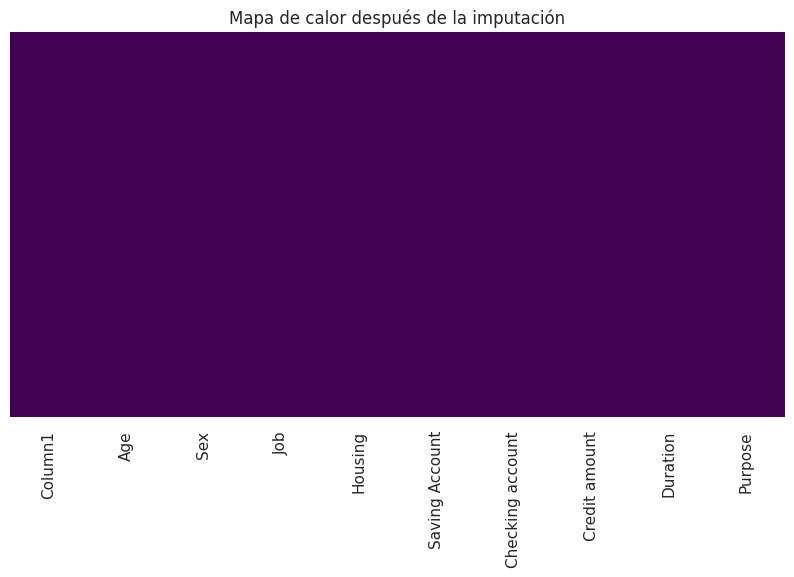

In [18]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor después de la imputación")
plt.show()

### 3. Boxplot de Outliers


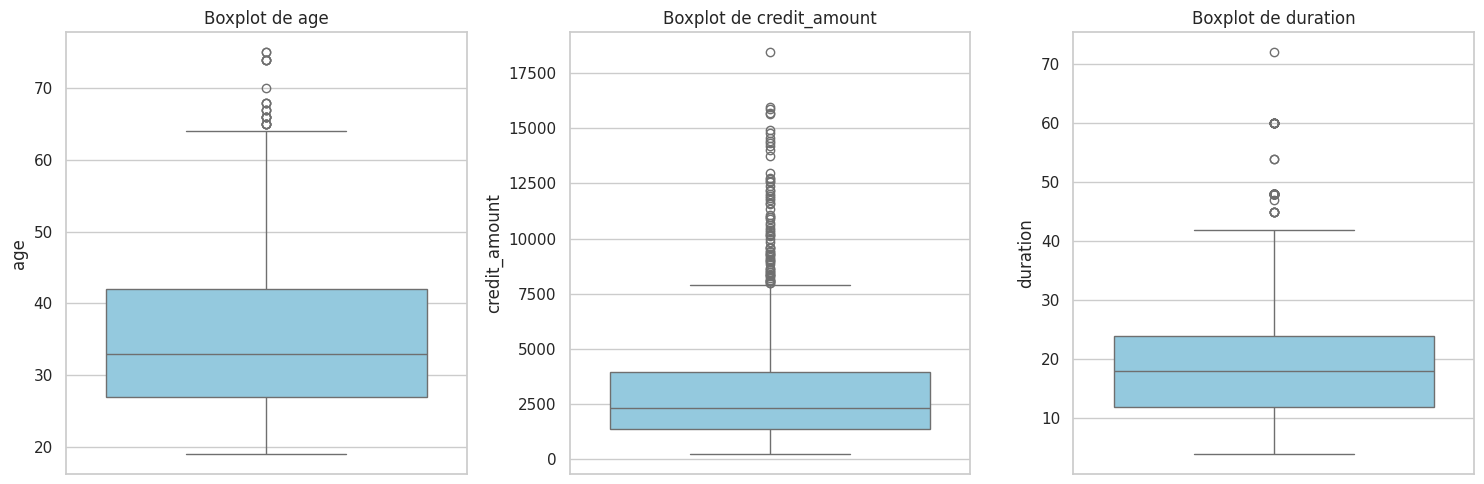

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["age", "credit_amount", "duration"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

## 4. Tratamiento de valores inconsistentes en texto y duplicados

In [19]:
# Nombres de columnas: estandarizar a minúsculas con guion bajo
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.columns.tolist()

['column1',
 'age',
 'sex',
 'job',
 'housing',
 'saving_account',
 'checking_account',
 'credit_amount',
 'duration',
 'purpose']

In [20]:
# La columna column1 es solo un índice de posición: no aporta información
df = df.drop(columns="column1")

In [21]:
# Valores de texto: quitar espacios y pasar a minúsculas
cols_texto = df.select_dtypes(exclude="number").columns
for col in cols_texto:
    antes = df[col].nunique()
    df[col] = df[col].str.strip().str.lower()
    print(f"{col}: {antes} -> {df[col].nunique()} categorías | {sorted(df[col].unique())}")

sex: 2 -> 2 categorías | ['female', 'male']
housing: 3 -> 3 categorías | ['free', 'own', 'rent']
saving_account: 5 -> 5 categorías | ['little', 'moderate', 'quite rich', 'rich', 'unknown']
checking_account: 4 -> 4 categorías | ['little', 'moderate', 'rich', 'unknown']
purpose: 8 -> 8 categorías | ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/tv', 'repairs', 'vacation/others']


Los valores de texto ya eran consistentes: después de limpiar espacios y mayúsculas el número de categorías no cambia, así que no había variantes como `Male`/`male ` duplicadas.

In [22]:
print("Filas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates()
print("Tamaño final:", df.shape)

Filas duplicadas: 0
Tamaño final: (1000, 9)


No hay registros duplicados en la base, por lo que no se elimina ninguna fila.